In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Load all CSV datasets (ensure they are uploaded to your Colab session or working directory)
customers = pd.read_csv("Datasets/customers.csv")
orders = pd.read_csv("Datasets/orders.csv")
order_items = pd.read_csv("Datasets/order_items.csv")
products = pd.read_csv("Datasets/products.csv")
payments = pd.read_csv("Datasets/payments.csv")
shipments = pd.read_csv("Datasets/shipments.csv")
returns = pd.read_csv("Datasets/returns.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [14]:
# Cleaning Order Items: validate quantities and prices
order_items["quantity"] = pd.to_numeric(order_items["quantity"], errors="coerce")
order_items["unit_price_at_purchase"] = (
    order_items["unit_price_at_purchase"]
    .astype(str)
    .str.replace(r"[^\d.]", "", regex=True) # Strips all currency symbols (₱, $) and formatting commas
    .replace("", np.nan)
    .astype(float)
)
order_items = order_items.dropna(
    subset=["order_id", "product_id", "quantity", "unit_price_at_purchase"]
)

# Cleaning Shipments (if required for Option A / B metrics)
shipments["ship_date"] = pd.to_datetime(shipments["ship_date"], errors= "coerce")
shipments["delivered_date"] = pd.to_datetime(
    shipments["delivered_date"], errors="coerce"
)
shipments = shipments.drop_duplicates(subset=["shipment_id"])

# ---------------------------------------------------------
# BUILD MASTER FACT TABLE (Option A Requirement)
# ---------------------------------------------------------
# Ensure orders has order_date parsed from order_datetime
orders["order_date"] = pd.to_datetime(orders["order_datetime"], errors="coerce")
orders = orders.drop_duplicates(subset=["order_id"]).dropna(
    subset=["order_date", "customer_id"]
)

# Merging orders -> order_items -> products -> customers
fact_df = (
    orders.merge(order_items, on="order_id", how="inner")
    .merge(products, on="product_id", how="inner")
    .merge(customers, on="customer_id", how="inner")
)

# Handle orphan records / validate join keys check
print(f"Total rows in Master Fact Table after inner joins: {len(fact_df):,}")

# Calculate line-item total revenue using the correct column
fact_df["line_revenue"] = fact_df["quantity"] * fact_df["unit_price_at_purchase"]

# ---------------------------------------------------------
# COMPUTE CORE KPIS
# ---------------------------------------------------------
total_revenue = fact_df["line_revenue"].sum()
total_orders = fact_df["order_id"].nunique()
total_items_sold = fact_df["quantity"].sum()
aov = total_revenue / total_orders

print("\n--- EXECUTIVE KPI SUMMARY ---")
print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Unique Orders: {total_orders:,}")
print(f"Total Items Sold: {total_items_sold:,}")
print(f"Average Order Value (AOV): ${aov:,.2f}")

Total rows in Master Fact Table after inner joins: 27,833

--- EXECUTIVE KPI SUMMARY ---
Total Revenue: $5,450,094.22
Total Unique Orders: 11,478
Total Items Sold: 58,889
Average Order Value (AOV): $474.83


In [16]:
# Merge orders with order_items, products, and customers
fact_df = (
    orders.merge(order_items, on="order_id", how="inner")
    .merge(products, on="product_id", how="inner")
    .merge(customers, on="customer_id", how="inner")
)

# Calculate total line item revenue using the correct column name
fact_df["line_revenue"] = fact_df["quantity"] * fact_df["unit_price_at_purchase"]
print(f"Fact table shape: {fact_df.shape}")

Fact table shape: (27833, 34)


In [18]:
# Merge orders with order_items, products, and customers
fact_df = (
    orders.merge(order_items, on="order_id", how="inner")
    .merge(products, on="product_id", how="inner")
    .merge(customers, on="customer_id", how="inner")
)

# Calculate total line item revenue using the correct column name
fact_df["line_revenue"] = fact_df["quantity"] * fact_df["unit_price_at_purchase"]
print(f"Fact table shape: {fact_df.shape}")

Fact table shape: (27833, 34)


In [19]:
total_revenue = fact_df["line_revenue"].sum()
total_orders = fact_df["order_id"].nunique()
aov = total_revenue / total_orders

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value (AOV): ${aov:,.2f}")

Total Revenue: $5,450,094.22
Total Orders: 11,478
Average Order Value (AOV): $474.83


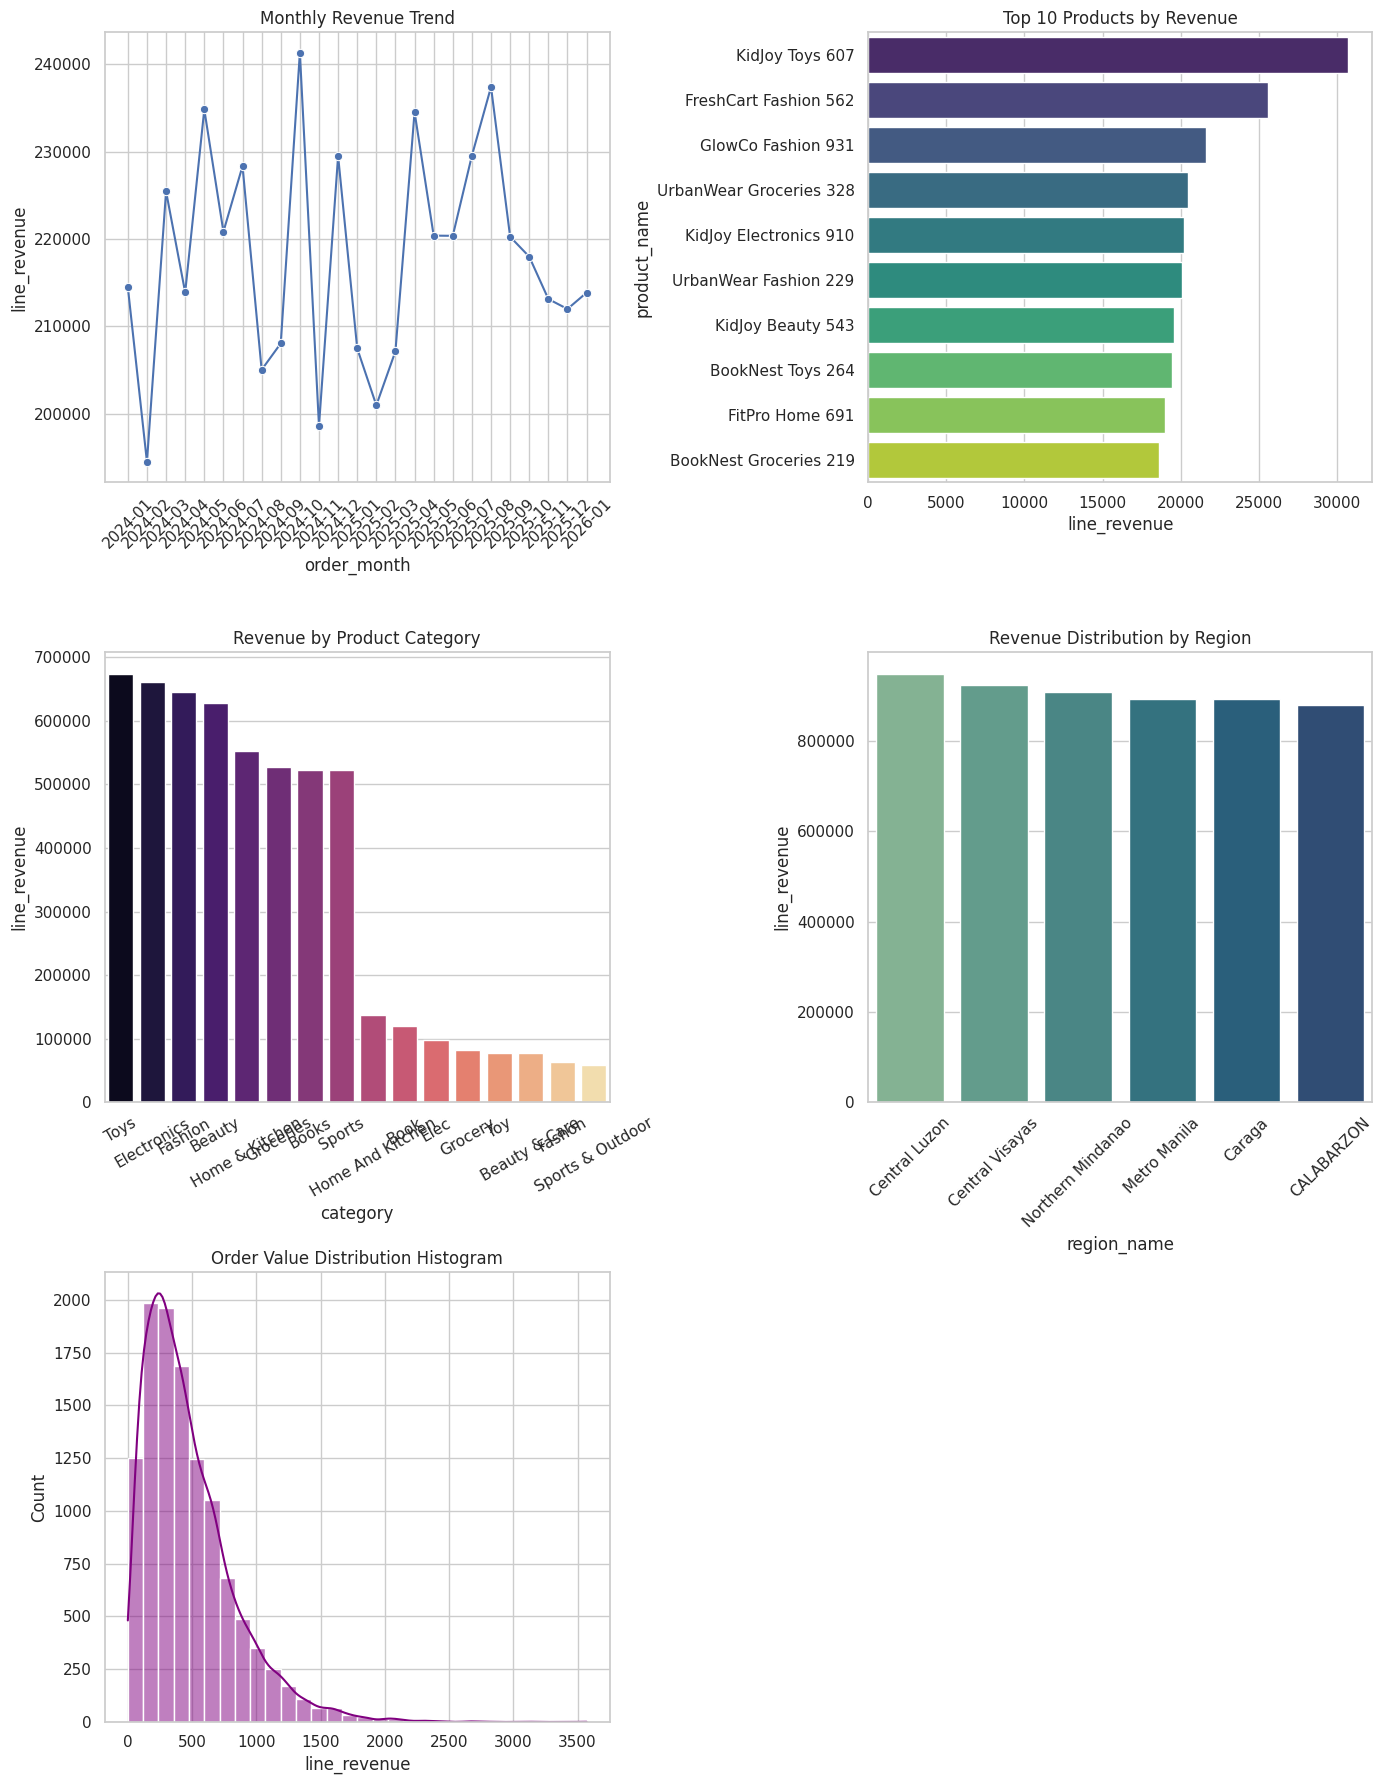

In [21]:
# Set general style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(14, 18))

# Chart 1: Monthly Revenue Trend
fact_df["order_month"] = fact_df["order_date"].dt.to_period("M")
monthly_rev = (
    fact_df.groupby("order_month")["line_revenue"].sum().reset_index()
)
monthly_rev["order_month"] = monthly_rev["order_month"].astype(str)
sns.lineplot(
    data=monthly_rev,
    x="order_month",
    y="line_revenue",
    marker="o",
    ax=axes[0, 0],
    color="b",
)
axes[0, 0].set_title("Monthly Revenue Trend")
axes[0, 0].tick_params(axis="x", rotation=45)

# Chart 2: Top 10 Products by Revenue
top_products = (
    fact_df.groupby("product_name")["line_revenue"]
    .sum()
    .reset_index()
    .sort_values(by="line_revenue", ascending=False)
    .head(10)
)
sns.barplot(
    data=top_products,
    x="line_revenue",
    y="product_name",
    ax=axes[0, 1],
    palette="viridis",
    hue="product_name",
    legend=False
)
axes[0, 1].set_title("Top 10 Products by Revenue")

# Chart 3: Revenue by Category
cat_rev = (
    fact_df.groupby("category")["line_revenue"]
    .sum()
    .reset_index()
    .sort_values(by="line_revenue", ascending=False)
)
sns.barplot(
    data=cat_rev,
    x="category",
    y="line_revenue",
    ax=axes[1, 0],
    palette="magma",
    hue="category",
    legend=False
)
axes[1, 0].set_title("Revenue by Product Category")
axes[1, 0].tick_params(axis="x", rotation=30)

# Chart 4: Revenue by Region
region_rev = (
    fact_df.groupby("region_name")["line_revenue"]
    .sum()
    .reset_index()
    .sort_values(by="line_revenue", ascending=False)
)
sns.barplot(
    data=region_rev,
    x="region_name",
    y="line_revenue",
    ax=axes[1, 1],
    palette="crest",
    hue="region_name",
    legend=False
)
axes[1, 1].set_title("Revenue Distribution by Region")
axes[1, 1].tick_params(axis="x", rotation=45)

# Chart 5: AOV / Customer Spend Distribution Histogram
order_totals = (
    fact_df.groupby("order_id")["line_revenue"].sum().reset_index()
)
sns.histplot(
    order_totals["line_revenue"],
    bins=30,
    kde=True,
    ax=axes[2, 0],
    color="purple",
)
axes[2, 0].set_title("Order Value Distribution Histogram")

# Hide unused subplot slot
axes[2, 1].axis("off")

plt.tight_layout()
plt.savefig("dashboard_charts_overview.png", dpi=300)
plt.show()

In [26]:
from google.colab import files

# Download all cleaned dataset deliverables & overview chart
files.download("Cleaned_customers.csv")
files.download("Cleaned_products.csv")
files.download("dashboard_charts_overview.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

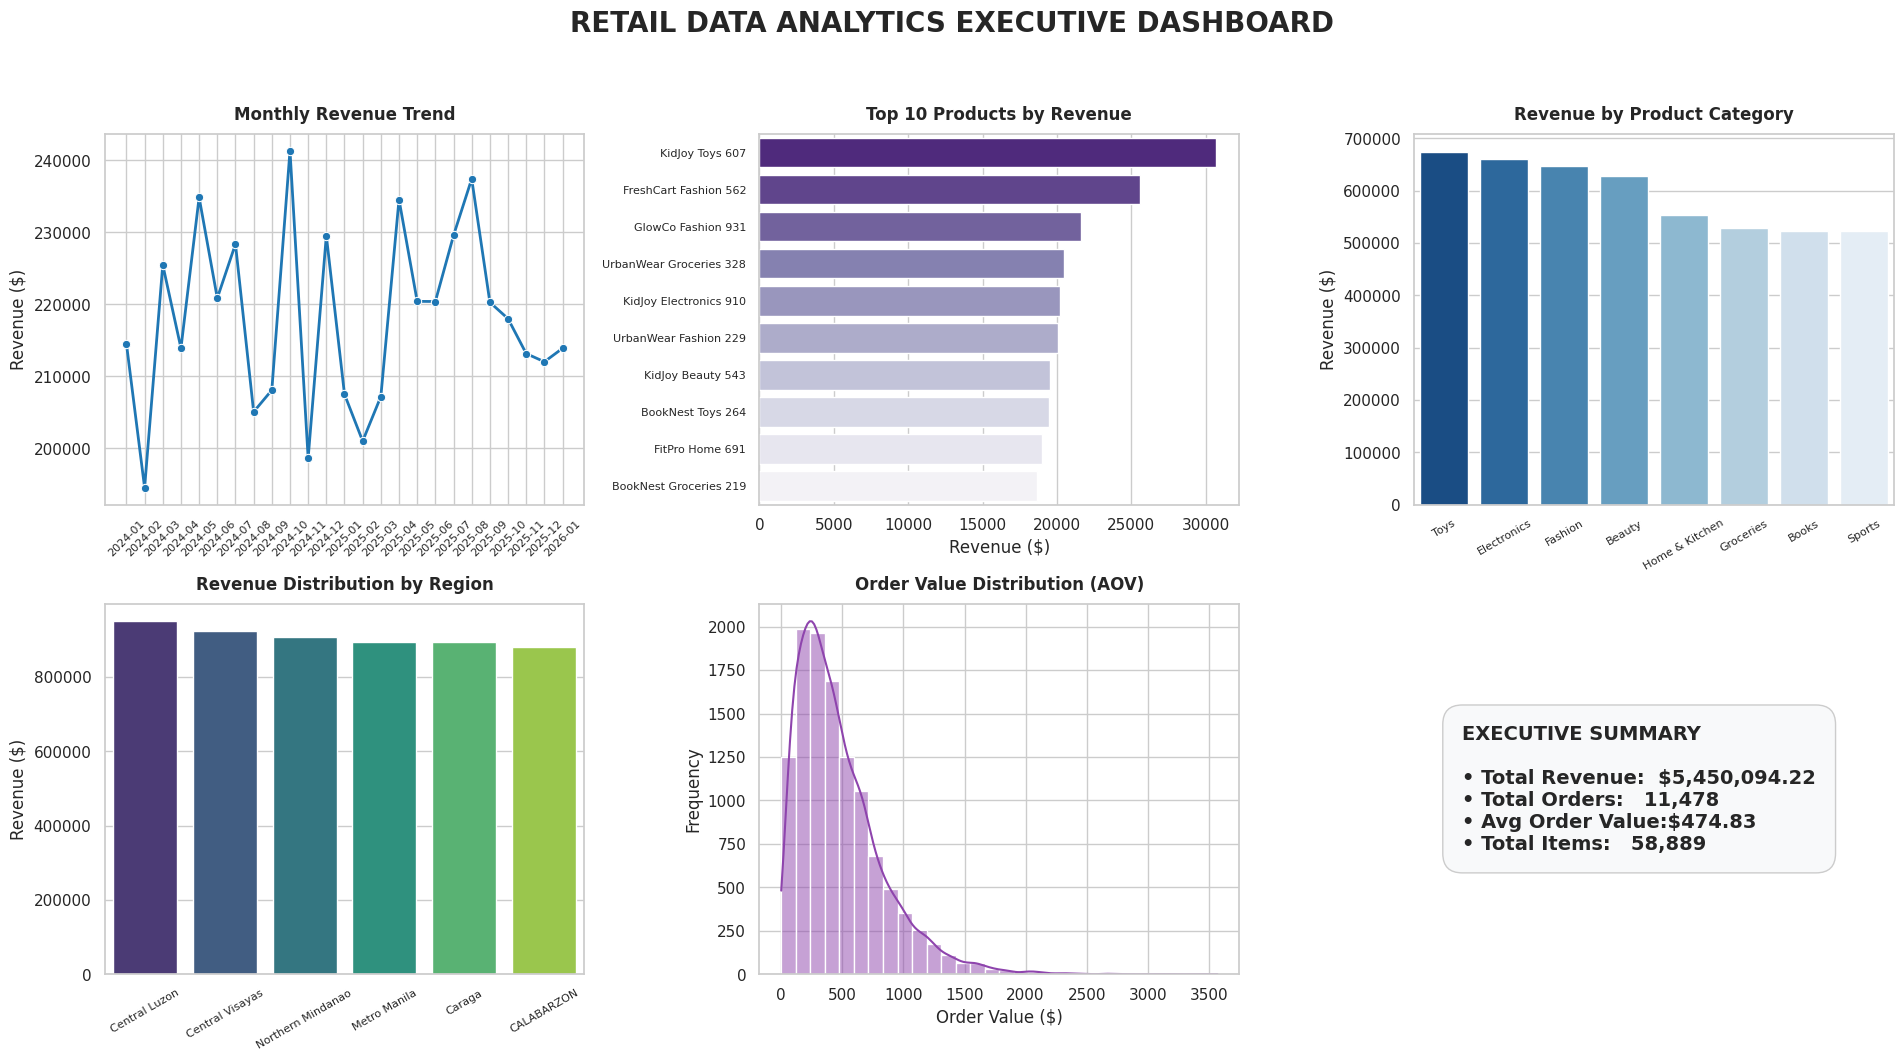

Dashboard successfully generated in 1920x1080 (16:9 ratio) resolution!


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set global theme and figure size (16:9 Ratio -> 19.2 x 10.8 inches)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(19.2, 10.8))
fig.suptitle(
    "RETAIL DATA ANALYTICS EXECUTIVE DASHBOARD",
    fontsize=20,
    fontweight="bold",
    y=0.98,
)

# --- Chart 1: Monthly Revenue Trend ---
fact_df["order_month"] = fact_df["order_date"].dt.to_period("M")
monthly_rev = (
    fact_df.groupby("order_month")["line_revenue"].sum().reset_index()
)
monthly_rev["order_month"] = monthly_rev["order_month"].astype(str)
sns.lineplot(
    data=monthly_rev,
    x="order_month",
    y="line_revenue",
    marker="o",
    color="#1f77b4",
    ax=axes[0, 0],
    linewidth=2,
)
axes[0, 0].set_title(
    "Monthly Revenue Trend", fontsize=12, fontweight="bold", pad=10
)
axes[0, 0].tick_params(axis="x", rotation=45, labelsize=8)
axes[0, 0].set_ylabel("Revenue ($)")
axes[0, 0].set_xlabel("")

# --- Chart 2: Top 10 Products by Revenue ---
top_products = (
    fact_df.groupby("product_name")["line_revenue"]
    .sum()
    .reset_index()
    .sort_values(by="line_revenue", ascending=False)
    .head(10)
)
sns.barplot(
    data=top_products,
    x="line_revenue",
    y="product_name",
    palette="Purples_r",
    hue="product_name",
    legend=False,
    ax=axes[0, 1],
)
axes[0, 1].set_title(
    "Top 10 Products by Revenue", fontsize=12, fontweight="bold", pad=10
)
axes[0, 1].set_xlabel("Revenue ($)")
axes[0, 1].set_ylabel("")
axes[0, 1].tick_params(axis="y", labelsize=8)

# --- Chart 3: Revenue by Product Category ---
cat_rev = (
    fact_df.groupby("category")["line_revenue"]
    .sum()
    .reset_index()
    .sort_values(by="line_revenue", ascending=False)
    .head(8)
)  # Top 8 categories for clean spacing
sns.barplot(
    data=cat_rev,
    x="category",
    y="line_revenue",
    palette="Blues_r",
    hue="category",
    legend=False,
    ax=axes[0, 2]
)
axes[0, 2].set_title(
    "Revenue by Product Category", fontsize=12, fontweight="bold", pad=10
)
axes[0, 2].tick_params(axis="x", rotation=30, labelsize=8)
axes[0, 2].set_ylabel("Revenue ($)")
axes[0, 2].set_xlabel("")

# --- Chart 4: Revenue Distribution by Region ---
region_rev = (
    fact_df.groupby("region_name")["line_revenue"]
    .sum()
    .reset_index()
    .sort_values(by="line_revenue", ascending=False)
)
sns.barplot(
    data=region_rev,
    x="region_name",
    y="line_revenue",
    palette="viridis",
    hue="region_name",
    legend=False,
    ax=axes[1, 0],
)
axes[1, 0].set_title(
    "Revenue Distribution by Region", fontsize=12, fontweight="bold", pad=10
)
axes[1, 0].tick_params(axis="x", rotation=30, labelsize=8)
axes[1, 0].set_ylabel("Revenue ($)")
axes[1, 0].set_xlabel("")

# --- Chart 5: Order Value Distribution (AOV Histogram) ---
order_totals = (
    fact_df.groupby("order_id")["line_revenue"].sum().reset_index()
)
sns.histplot(
    order_totals["line_revenue"],
    bins=30,
    kde=True,
    color="#8e44ad",
    ax=axes[1, 1],
)
axes[1, 1].set_title(
    "Order Value Distribution (AOV)", fontsize=12, fontweight="bold", pad=10
)
axes[1, 1].set_xlabel("Order Value ($)")
axes[1, 1].set_ylabel("Frequency")

# --- Chart 6 (Fills the 2x3 Grid): Summary KPI Box ---
axes[1, 2].axis("off")  # Remove axis lines for custom summary box
kpi_text = (
    f"EXECUTIVE SUMMARY\n\n"
    f"• Total Revenue:  ${total_revenue:,.2f}\n"
    f"• Total Orders:   {total_orders:,}\n"
    f"• Avg Order Value:${aov:,.2f}\n"
    f"• Total Items:   {total_items_sold:,}"
)
axes[1, 2].text(
    0.1,
    0.5,
    kpi_text,
    fontsize=14,
    fontweight="bold",
    va="center",
    bbox=dict(boxstyle="round,pad=1", facecolor="#f8f9fa", edgecolor="#cccccc"),
)

# Adjust layout spacing
plt.tight_layout(rect=[0, 0, 1, 0.95])

# 2. Export with exact 1920x1080 resolution (19.2 inches * 100 dpi = 1920px width)
plt.savefig(
    "Python_Data_Visualization_Dashboard_1920x1080.png",
    dpi=100,
    bbox_inches="tight",
)
plt.show()

print("Dashboard successfully generated in 1920x1080 (16:9 ratio) resolution!")

In [28]:
from google.colab import files

# Download the updated widescreen dashboard image
files.download("Python_Data_Visualization_Dashboard_1920x1080.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>